# Groundwater Quality in India, 2024: A Data Visualization Case Study
**Student:** Joshika A S  |  **Course:** Data Visualisation  |  **Department:** Computer Science Engineering

## 1. Problem statement and objectives
**Problem.** Groundwater is the main source of drinking water for much of India, but it can carry nitrate, fluoride, arsenic, iron, uranium and high salinity. Which parameters most often exceed drinking-water limits, where, and does the picture change between pre-monsoon and post-monsoon?

**Objectives**
1. Measure how often each key parameter exceeds its drinking-water limit.
2. Compare states on exceedance rates and spot regional patterns.
3. Compare pre-monsoon and post-monsoon quality.
4. Examine how parameters relate to one another (nitrate against salinity as measured by EC).
5. Communicate the findings with three tools, including an interactive Tableau dashboard.
6. Demonstrate a misleading chart and an ethical redesign.

## 2. Dataset
**Source:** Central Ground Water Board (CGWB), Ministry of Jal Shakti, *Ground Water Quality Data (2024)*, a 163-page PDF table (file `CGWB_GWQ_2024.pdf`).
Each row is one monitoring station in one season (Pre-Monsoon or Post-Monsoon) with its location (state, district, block, station, latitude, longitude) and laboratory measurements (pH, EC, TDS, major ions, fluoride, iron, arsenic, uranium and other metals).

**Limits used.** Drinking-water limits follow BIS IS 10500:2012: nitrate 45 mg/L, fluoride 1.5 mg/L, TDS 2000 mg/L (permissible limit), arsenic 10 µg/L (0.01 mg/L). Iron uses 1.0 mg/L, the level CGWB reports against (the BIS acceptable limit is stricter, 0.3 mg/L). Uranium uses 30 µg/L, a commonly adopted value; verify before quoting it formally.

## 3. Tools
| Tool | Used for |
|---|---|
| Matplotlib (Python) | Bar chart, histogram, scatter plot, line plot, misleading and corrected charts |
| Seaborn (Python) | Heatmap and boxplot |
| Tableau | Interactive dashboard (see `Tableau_Dashboard_Build_Guide.md`) |

In [5]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go          # interactive charts (pip install plotly if missing)
import plotly.io as pio
warnings.filterwarnings('ignore')
os.makedirs('charts', exist_ok=True)

TEAL, NAVY, GREY, AMBER, RED = '#147483', '#182F4B', '#546271', '#E0A030', '#C0392B'
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.dpi': 100})
pd.set_option('display.width', 160)
pio.renderers.default = 'notebook_connected'   # Plotly charts load plotly.js from the web; use 'notebook' to work offline

## 4. Load the data
The PDF was converted to a table with `pdfplumber` (one table per page). The extraction cell below is optional: it only runs if `RUN_EXTRACTION = True`. The extracted file is supplied as `CGWB_Groundwater_Quality_2024_Raw_Extracted.csv`.

In [6]:
RUN_EXTRACTION = False   # set True to rebuild the CSV from the PDF (needs pdfplumber, takes a few minutes)
COLS = ['S_No','Year','Season','State','District','Block','Station','Longitude','Latitude','pH','EC_uS_cm','TDS_mgL',
        'CO3_mgL','HCO3_mgL','Total_Alkalinity_mgL','Cl_mgL','NO3_mgL','SO4_mgL','PO4_mgL','SiO2_mgL','F_mgL',
        'Total_Hardness_mgL','Ca_mgL','Mg_mgL','Na_mgL','K_mgL','Fe_mgL','As_ppb','U_ppb','Mn_mgL','Cu_mgL',
        'Pb_mgL','Zn_mgL','Ni_mgL','Cd_mgL','Cr_mgL']
from pathlib import Path
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RAW = ROOT / 'data' / 'raw' / 'CGWB_Groundwater_Quality_2024_Raw_Extracted.csv'
PROCESSED = ROOT / 'data' / 'processed' / 'CGWB_Groundwater_Quality_2024_Cleaned.csv'

if RUN_EXTRACTION:
    import pdfplumber
    rows = []
    with pdfplumber.open('CGWB_GWQ_2024.pdf') as pdf:
        for page in pdf.pages:
            for table in page.extract_tables():
                rows += [r for r in table if r and r[0] and r[0].strip().isdigit() and len(r) == 36]
            page.flush_cache()
    tmp = pd.DataFrame(rows, columns=COLS)
    for c in COLS[7:]:
        tmp[c] = pd.to_numeric(tmp[c].replace({'-': None, '': None}), errors='coerce')
    tmp.to_csv(RAW, index=False)

raw = pd.read_csv(RAW)
print('Raw shape:', raw.shape)
print(raw.iloc[:3, :12].to_string())

Raw shape: (15189, 36)
   S_No  Year       Season        State       District Block                     Station  Longitude  Latitude    pH  EC_uS_cm  TDS_mgL
0     1  2024  Pre-Monsoon  A&N Islands  South Andaman   NaN  Corbyn's Cove (port Blair)    92.7458   11.6444  7.44     578.0    310.0
1     2  2024  Pre-Monsoon  A&N Islands  South Andaman   NaN                   Sippighat    92.7300   11.6025  7.24     720.0    443.0
2     3  2024  Pre-Monsoon  A&N Islands  South Andaman   NaN         Saidpur(port Blair)    92.7433   11.6564  7.50     431.0    276.0


## 5. Initial data quality assessment

In [7]:
print('Rows:', len(raw), '| Columns:', raw.shape[1])
print('Seasons:', raw['Season'].value_counts().to_dict())
print('State labels:', raw['State'].nunique())
print(sorted(raw['State'].unique()))
print()
missing = (raw.isna().mean() * 100).round(1)
print('Missing values (%), columns with any missing:')
print(missing[missing > 0].sort_values(ascending=False).to_string())
print()
print('Exact duplicate rows (ignoring serial number):', raw.duplicated(subset=[c for c in raw.columns if c != 'S_No']).sum())
print('Latitude range:', raw['Latitude'].min(), 'to', raw['Latitude'].max())
print('Longitude range:', raw['Longitude'].min(), 'to', raw['Longitude'].max())
print('Negative arsenic values:', int((raw['As_ppb'] < 0).sum()))

Rows: 15189 | Columns: 36
Seasons: {'Pre-Monsoon': 7794, 'Post-Monsoon': 7395}
State labels: 37
['A&N Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Diu', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'New Delhi', 'ODISHA', 'Odisha', 'Punjab', 'RAJASTHAN', 'Rajasthan', 'Tamil Nadu', 'Tamilnadu', 'Telangana', 'Tripura', 'UT of Puducherry', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Missing values (%), columns with any missing:
Cd_mgL                  64.1
Ni_mgL                  63.2
SiO2_mgL                60.8
PO4_mgL                 58.5
Cr_mgL                  53.8
Pb_mgL                  46.8
Mn_mgL                  39.9
Zn_mgL                  38.2
Cu_mgL                  38.0
As_ppb                  37.3
Fe_mgL                  33.9
U_ppb                   30.6
Total_Alkalinity_mg

**Findings.** The PDF-to-table conversion shows the same issues the raw table has:
- State names are inconsistent (for example `ODISHA` and `Odisha`, `Tamilnadu` and `Tamil Nadu`, `New Delhi` and `Delhi`).
- Some coordinates are swapped (latitude in the longitude column) or impossible for India.
- A few exact duplicate rows exist and one arsenic value is slightly negative.
- Many metal columns are blank. A dash in the PDF means *not analysed*, so these are genuine missing values, not zeros.

## 6. Cleaning and preprocessing
| Step | Reason |
|---|---|
| Standardise state names | Same state counted under two labels would split its totals |
| Swap reversed coordinates; blank impossible ones | Needed for any map; invalid points would sit outside India |
| Remove exact duplicate rows | Avoids double counting a station reading |
| Set the one negative arsenic value to 0 | A concentration cannot be negative; it is a rounding artefact |
| Keep missing measurements blank (no imputation) | Filling them would invent data; every percentage uses only samples that were measured |
| Add exceedance flags | One row per sample, 1 if the reading is above its limit, so Tableau can average them |

In [8]:
df = raw.copy()
n_raw, states_raw = len(df), df['State'].nunique()

state_map = {'ODISHA': 'Odisha', 'RAJASTHAN': 'Rajasthan', 'Tamilnadu': 'Tamil Nadu', 'New Delhi': 'Delhi',
             'UT of Puducherry': 'Puducherry', 'A&N Islands': 'Andaman & Nicobar Islands', 'Diu': 'Daman & Diu'}
df['State'] = df['State'].replace(state_map)

# coordinates: swap where latitude/longitude are reversed, blank values outside India
swap = (df['Longitude'] < 40) & (df['Latitude'] > 50)
df.loc[swap, ['Latitude', 'Longitude']] = df.loc[swap, ['Longitude', 'Latitude']].values
bad = ~df['Latitude'].between(6, 38) | ~df['Longitude'].between(67, 98)
df.loc[bad, ['Latitude', 'Longitude']] = np.nan

n_dups = int(df.duplicated(subset=[c for c in df.columns if c != 'S_No']).sum())
df = df.drop_duplicates(subset=[c for c in df.columns if c != 'S_No']).reset_index(drop=True)
df.loc[df['As_ppb'] < 0, 'As_ppb'] = 0
df = df.drop(columns=['S_No']); df.insert(0, 'Record_ID', range(1, len(df) + 1))

print(pd.DataFrame({'Check': ['Rows', 'State labels', 'Duplicate rows', 'Swapped coordinates', 'Invalid coordinates blanked'],
                    'Before': [n_raw, states_raw, n_dups, int(swap.sum()), int(bad.sum())],
                    'After': [len(df), df['State'].nunique(), 0, 0, 0]}).to_string(index=False))

                      Check  Before  After
                       Rows   15189  15185
               State labels      37     33
             Duplicate rows       4      0
        Swapped coordinates     234      0
Invalid coordinates blanked      31      0


In [9]:
# Drinking-water limits (BIS IS 10500:2012; iron per CGWB reporting; uranium commonly adopted value)
LIMITS = {'Nitrate (NO3)': ('NO3_mgL', 45, 'mg/L'), 'Fluoride (F)': ('F_mgL', 1.5, 'mg/L'),
          'TDS': ('TDS_mgL', 2000, 'mg/L'), 'Iron (Fe)': ('Fe_mgL', 1.0, 'mg/L'),
          'Uranium (U)': ('U_ppb', 30, 'ppb'), 'Arsenic (As)': ('As_ppb', 10, 'ppb')}
for name, (col, lim, unit) in LIMITS.items():
    df['Exceeds_' + col] = np.where(df[col].isna(), np.nan, (df[col] > lim).astype(float))

flag_cols = ['Exceeds_' + c for c, _, _ in LIMITS.values()]
df.to_csv(PROCESSED, index=False)

# Tableau-ready summary: one row per State x Season x Parameter
rows = []
for name, (col, lim, unit) in LIMITS.items():
    g = df.dropna(subset=[col]).groupby(['State', 'Season'])[col].agg(Samples='count', Exceeding=lambda s: int((s > lim).sum())).reset_index()
    g['Parameter'], g['Limit'], g['Unit'] = name, lim, unit
    rows.append(g)
summary = pd.concat(rows)
summary['Exceedance_Pct'] = (summary['Exceeding'] / summary['Samples'] * 100).round(2)
summary[['State', 'Season', 'Parameter', 'Limit', 'Unit', 'Samples', 'Exceeding', 'Exceedance_Pct']].to_csv(ROOT / 'dashboard' / 'tableau' / 'Tableau_State_Season_Parameter.csv', index=False)
print('Saved cleaned file:', df.shape, '| Tableau summary:', summary.shape)

Saved cleaned file: (15185, 42) | Tableau summary: (350, 8)


In [10]:
# Reusable numbers
exceed = {name: float(df['Exceeds_' + col].mean() * 100) for name, (col, _, _) in LIMITS.items()}
n_measured = {name: int(df[col].notna().sum()) for name, (col, _, _) in LIMITS.items()}
state_n = df['State'].value_counts()
big_states = state_n[state_n >= 100].index.tolist()          # states with at least 100 samples
print('Share of samples above the limit (%):')
print(pd.Series(exceed).round(1).sort_values(ascending=False).to_string())
print('\nStates with at least 100 samples:', len(big_states), 'of', df['State'].nunique())

Share of samples above the limit (%):
Nitrate (NO3)    25.3
Iron (Fe)        12.5
Fluoride (F)      6.8
Uranium (U)       6.6
TDS               6.2
Arsenic (As)      3.4

States with at least 100 samples: 25 of 33


## Interactive Plotly dashboard: all 13 visualizations
Use the shared filters to explore the charts by state, season, and parameter. The 13 numbered tabs preserve the analysis below while presenting each visualization as an interactive Plotly chart. Select **All** to compare the full dataset. The season-comparison charts always retain both seasons when needed for a fair comparison. Use the export button to save the current filtered charts as HTML files in `charts/`.


In [11]:
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output
from plotly.subplots import make_subplots

PARAMETER_NAMES = list(LIMITS)
STATE_OPTIONS = ['All states'] + sorted(df['State'].dropna().unique().tolist())
SEASON_OPTIONS = ['All seasons'] + sorted(df['Season'].dropna().unique().tolist())
PARAMETER_OPTIONS = ['All parameters'] + PARAMETER_NAMES
FILTER_COLORS = {'Within limit': '#AAB7C4', 'Above limit': RED}

state_filter = widgets.Dropdown(options=STATE_OPTIONS, value='All states', description='State:', layout=widgets.Layout(width='260px'))
season_filter = widgets.Dropdown(options=SEASON_OPTIONS, value='All seasons', description='Season:', layout=widgets.Layout(width='260px'))
parameter_filter = widgets.Dropdown(options=PARAMETER_OPTIONS, value='All parameters', description='Parameter:', layout=widgets.Layout(width='340px'))
export_button = widgets.Button(description='Export current charts', icon='download', button_style='')
dashboard_output = widgets.Output()
current_dashboard_figures = []


def dashboard_data(state_value, season_value):
    data = df
    if state_value != 'All states':
        data = data[data['State'] == state_value]
    if season_value != 'All seasons':
        data = data[data['Season'] == season_value]
    return data


def selected_parameters(parameter_value):
    if parameter_value == 'All parameters':
        return list(LIMITS.items())
    return [(parameter_value, LIMITS[parameter_value])]


def finish_figure(fig, height=520):
    fig.update_layout(template='plotly_white', height=height, margin=dict(l=55, r=35, t=75, b=55),
                      font=dict(family='Arial, sans-serif', size=12), hoverlabel=dict(namelength=-1))
    return fig


def build_dashboard_figures(state_value, season_value, parameter_value):
    data = dashboard_data(state_value, season_value)
    comparison_data = dashboard_data(state_value, 'All seasons')
    chosen = selected_parameters(parameter_value)
    figures = []

    # 1. Exceedance rates by parameter.
    rate_rows = []
    for name, (column, limit, unit) in chosen:
        measured = data[column].dropna()
        rate_rows.append({'Parameter': name, 'Above limit (%)': (measured > limit).mean() * 100 if len(measured) else 0,
                          'Samples': len(measured), 'Limit': limit, 'Unit': unit})
    rates = pd.DataFrame(rate_rows).sort_values('Above limit (%)')
    fig = px.bar(rates, x='Above limit (%)', y='Parameter', orientation='h', text='Above limit (%)',
                 color='Above limit (%)', color_continuous_scale='YlOrRd', hover_data=['Samples', 'Limit', 'Unit'])
    fig.update_traces(texttemplate='%{x:.1f}%', textposition='outside')
    fig.update_layout(title='1. Samples above drinking-water limits', coloraxis_showscale=False, xaxis_title='Samples above limit (%)')
    figures.append(finish_figure(fig, 440))

    # 2. State-by-parameter exceedance heatmap.
    heat_values = {}
    for name, (column, limit, unit) in chosen:
        measured = data.dropna(subset=[column]).groupby('State')[column]
        heat_values[name] = measured.apply(lambda values: (values > limit).mean() * 100)
    heat = pd.DataFrame(heat_values).sort_index()
    fig = go.Figure(go.Heatmap(z=heat.values, x=heat.columns, y=heat.index, colorscale='YlOrRd', zmin=0,
                               colorbar=dict(title='Above limit (%)'), hovertemplate='%{y}<br>%{x}: %{z:.1f}%<extra></extra>'))
    fig.update_layout(title='2. Exceedance by state and parameter', xaxis_title='Parameter', yaxis_title='State')
    figures.append(finish_figure(fig, max(420, 24 * len(heat) + 150)))

    # 3. Distribution for the selected parameter (nitrate when All is selected).
    hist_name, (hist_column, hist_limit, hist_unit) = (chosen[0] if len(chosen) == 1 else ('Nitrate (NO3)', LIMITS['Nitrate (NO3)']))
    hist_data = data[hist_column].dropna()
    if hist_name == 'Nitrate (NO3)':
        hist_data = hist_data[hist_data <= 300]
    fig = px.histogram(x=hist_data, nbins=40, labels={'x': f'{hist_name} ({hist_unit})', 'y': 'Samples'},
                       title=f'3. Distribution of {hist_name}')
    fig.add_vline(x=hist_limit, line_dash='dash', line_color=RED, annotation_text=f'Limit {hist_limit:g} {hist_unit}')
    figures.append(finish_figure(fig, 440))

    # 4. Distribution by state for the selected parameter (fluoride when All is selected).
    box_name, (box_column, box_limit, box_unit) = (chosen[0] if len(chosen) == 1 else ('Fluoride (F)', LIMITS['Fluoride (F)']))
    box_data = data.dropna(subset=[box_column]).copy()
    state_rates = box_data.groupby('State')[box_column].apply(lambda values: (values > box_limit).mean())
    top_states = state_rates.sort_values(ascending=False).head(8).index
    box_data = box_data[box_data['State'].isin(top_states) & (box_data[box_column] > 0)]
    fig = px.box(box_data, x='State', y=box_column, points='outliers', color_discrete_sequence=[TEAL],
                 title=f'4. {box_name} distribution in highest-exceedance states')
    fig.add_hline(y=box_limit, line_dash='dash', line_color=RED, annotation_text=f'Limit {box_limit:g} {box_unit}')
    fig.update_yaxes(type='log', title=f'{box_name} ({box_unit}, log scale)')
    fig.update_xaxes(title='', tickangle=-25)
    figures.append(finish_figure(fig, 500))

    # 5. Selected parameter against electrical conductivity.
    scatter_name, (scatter_column, scatter_limit, scatter_unit) = (chosen[0] if len(chosen) == 1 else ('Nitrate (NO3)', LIMITS['Nitrate (NO3)']))
    scatter_data = data.dropna(subset=['EC_uS_cm', scatter_column, 'Station', 'District', 'State'])
    scatter_data = scatter_data[(scatter_data['EC_uS_cm'] > 0) & (scatter_data[scatter_column] > 0)]
    if len(scatter_data) > 5000:
        scatter_data = scatter_data.sample(5000, random_state=42)
    scatter_data = scatter_data.copy()
    scatter_data['Reading'] = np.where(scatter_data[scatter_column] > scatter_limit, 'Above limit', 'Within limit')
    correlation = scatter_data['EC_uS_cm'].corr(scatter_data[scatter_column], method='spearman') if len(scatter_data) > 1 else np.nan
    fig = px.scatter(scatter_data, x='EC_uS_cm', y=scatter_column, color='Reading', color_discrete_map=FILTER_COLORS,
                     hover_data=['Station', 'District', 'State', 'Season'], opacity=0.55,
                     title=f'5. {scatter_name} vs electrical conductivity (Spearman rho = {correlation:.2f})')
    fig.update_xaxes(type='log', title='Electrical conductivity (µS/cm)')
    fig.update_yaxes(type='log', title=f'{scatter_name} ({scatter_unit})')
    fig.add_hline(y=scatter_limit, line_dash='dash', line_color=RED)
    figures.append(finish_figure(fig, 520))

    # 6. Seasonal exceedance comparison; retain both seasons for the comparison.
    season_rows = []
    for name, (column, limit, unit) in chosen:
        for season_name, season_group in comparison_data.groupby('Season'):
            measured = season_group[column].dropna()
            season_rows.append({'Season': season_name, 'Parameter': name,
                                'Above limit (%)': (measured > limit).mean() * 100 if len(measured) else 0,
                                'Samples': len(measured)})
    season_frame = pd.DataFrame(season_rows)
    fig = px.line(season_frame, x='Season', y='Above limit (%)', color='Parameter', markers=True,
                  custom_data=['Samples'], title='6. Exceedance rates by season (both seasons retained)')
    fig.update_traces(hovertemplate='%{fullData.name}<br>%{x}: %{y:.1f}%<br>Samples: %{customdata[0]}<extra></extra>')
    figures.append(finish_figure(fig, 480))

    # 7. Small-multiple station maps by parameter.
    map_parameters = chosen
    map_titles = [name for name, _ in map_parameters]
    map_fig = make_subplots(rows=2, cols=3, subplot_titles=map_titles, horizontal_spacing=0.05, vertical_spacing=0.12)
    mapped = data.dropna(subset=['Latitude', 'Longitude'])
    for index, (name, (column, limit, unit)) in enumerate(map_parameters):
        row_index, col_index = index // 3 + 1, index % 3 + 1
        measured = mapped.dropna(subset=[column]).copy()
        measured['Reading'] = np.where(measured[column] > limit, 'Above limit', 'Within limit')
        for reading in ['Within limit', 'Above limit']:
            points = measured[measured['Reading'] == reading]
            map_fig.add_trace(go.Scattergl(x=points['Longitude'], y=points['Latitude'], mode='markers',
                                           name=reading, legendgroup=reading, showlegend=(index == 0),
                                           marker=dict(size=4, color=FILTER_COLORS[reading], opacity=0.75),
                                           customdata=points[['Station', 'District', 'State', 'Season', column]].values,
                                           hovertemplate='%{customdata[0]}<br>%{customdata[1]}, %{customdata[2]}<br>%{customdata[3]}<br>' + f'{name}: ' + '%{customdata[4]:.2f} ' + f'{unit}<extra></extra>'),
                              row=row_index, col=col_index)
        map_fig.update_xaxes(range=[67, 98], visible=False, row=row_index, col=col_index)
        map_fig.update_yaxes(range=[5, 38], visible=False, row=row_index, col=col_index)
    map_fig.update_layout(title='7. Station exceedance maps by parameter', height=760, template='plotly_white',
                          margin=dict(l=20, r=20, t=90, b=35), legend=dict(orientation='h', y=-0.03))
    figures.append(map_fig)

    # 8. Paired station seasonal comparison.
    pair_source = comparison_data.dropna(subset=[box_column]).copy()
    station_key = ['State', 'District', 'Block', 'Station']
    if not pair_source.empty:
        paired_rows = pair_source.groupby(station_key, dropna=False)['Season'].transform('nunique') == 2
        pair_source = pair_source[paired_rows]
    if not pair_source.empty:
        pair_values = pair_source.groupby(station_key + ['Season'], dropna=False)[box_column].mean().unstack('Season').dropna()
    else:
        pair_values = pd.DataFrame(columns=['Pre-Monsoon', 'Post-Monsoon'])
    pair_rows = []
    if not pair_values.empty:
        for season_name in ['Pre-Monsoon', 'Post-Monsoon']:
            if season_name in pair_values:
                pair_rows.append({'Season': season_name, 'Above limit (%)': (pair_values[season_name] > box_limit).mean() * 100})
    pair_frame = pd.DataFrame(pair_rows)
    fig = go.Figure()
    if len(pair_frame) == 2:
        fig.add_trace(go.Scatter(x=pair_frame['Above limit (%)'], y=[box_name], mode='lines', line=dict(color=GREY, width=3), showlegend=False, hoverinfo='skip'))
        for _, row in pair_frame.iterrows():
            fig.add_trace(go.Scatter(x=[row['Above limit (%)']], y=[box_name], mode='markers+text', name=row['Season'],
                                     text=[f"{row['Above limit (%)']:.1f}%"], textposition='middle right', marker=dict(size=13),
                                     hovertemplate=f"{row['Season']}: %{{x:.1f}}%<extra></extra>"))
    else:
        fig.add_annotation(text='No stations with measurements in both seasons for these filters.', showarrow=False, x=0.5, y=0.5, xref='paper', yref='paper')
    fig.update_layout(title=f'8. Same-station seasonal comparison: {box_name}', xaxis_title='Stations above limit (%)', yaxis_title='')
    figures.append(finish_figure(fig, 440))

    # 9. Number of exceedances per fully measured sample and common pairs.
    full = data[data[flag_cols].notna().all(axis=1)]
    exceed_counts = full[flag_cols].sum(axis=1).astype(int).value_counts().sort_index()
    count_labels = [str(index) if index < 3 else '3+' for index in exceed_counts.index]
    count_frame = pd.DataFrame({'Exceedances': count_labels, 'Samples': exceed_counts.values})
    count_frame = count_frame.groupby('Exceedances', sort=False, as_index=False)['Samples'].sum()
    fig = px.bar(count_frame, x='Exceedances', y='Samples', text='Samples', title='9. Limits exceeded per fully measured sample',
                 color='Exceedances', color_discrete_sequence=[GREY, AMBER, RED, '#8F2633'])
    fig.update_layout(showlegend=False)
    figures.append(finish_figure(fig, 440))

    # 10. Spearman correlation matrix, or selected parameter against all others.
    corr_columns = {'pH': 'pH', 'EC_uS_cm': 'EC', 'TDS_mgL': 'TDS', 'Cl_mgL': 'Cl', 'SO4_mgL': 'SO4',
                    'NO3_mgL': 'NO3', 'HCO3_mgL': 'HCO3', 'Ca_mgL': 'Ca', 'Mg_mgL': 'Mg',
                    'Na_mgL': 'Na', 'F_mgL': 'F', 'Fe_mgL': 'Fe', 'As_ppb': 'As', 'U_ppb': 'U'}
    corr_frame = data[list(corr_columns)].rename(columns=corr_columns).corr(method='spearman')
    selected_corr_name = {'Nitrate (NO3)': 'NO3', 'Fluoride (F)': 'F', 'TDS': 'TDS', 'Iron (Fe)': 'Fe',
                          'Uranium (U)': 'U', 'Arsenic (As)': 'As'}
    if parameter_value != 'All parameters':
        corr_frame = corr_frame.loc[[selected_corr_name[parameter_value]], :]
    fig = go.Figure(go.Heatmap(z=corr_frame.values, x=corr_frame.columns, y=corr_frame.index, zmin=-1, zmax=1, zmid=0,
                               colorscale='RdBu', text=np.round(corr_frame.values, 2), texttemplate='%{text}',
                               colorbar=dict(title='Spearman rho'), hovertemplate='%{y} vs %{x}: %{z:.2f}<extra></extra>'))
    fig.update_layout(title='10. Spearman correlation between water-quality parameters', xaxis_title='', yaxis_title='')
    figures.append(finish_figure(fig, 520 if parameter_value == 'All parameters' else 300))

    # 11. Piper diagram with the four water-type groups.
    ion_factors = {'Ca_mgL': 20.04, 'Mg_mgL': 12.15, 'Na_mgL': 22.99, 'K_mgL': 39.10,
                   'HCO3_mgL': 61.02, 'CO3_mgL': 30.00, 'Cl_mgL': 35.45, 'SO4_mgL': 48.03}
    piper = data.dropna(subset=list(ion_factors)).copy()
    for column, factor in ion_factors.items():
        piper[column] = piper[column] / factor
    piper = piper[(piper[list(ion_factors)] >= 0).all(axis=1)]
    cations = piper[['Ca_mgL', 'Mg_mgL', 'Na_mgL', 'K_mgL']].sum(axis=1)
    anions = piper[['HCO3_mgL', 'CO3_mgL', 'Cl_mgL', 'SO4_mgL']].sum(axis=1)
    piper = piper[(cations > 0) & (anions > 0)]
    cations, anions = cations.loc[piper.index], anions.loc[piper.index]
    calcium, magnesium = piper['Ca_mgL'] / cations, piper['Mg_mgL'] / cations
    sodium = (piper['Na_mgL'] + piper['K_mgL']) / cations
    bicarbonate = (piper['HCO3_mgL'] + piper['CO3_mgL']) / anions
    chloride, sulphate = piper['Cl_mgL'] / anions, piper['SO4_mgL'] / anions
    water_types = np.select([(calcium + magnesium >= 0.5) & (bicarbonate >= 0.5),
                             (calcium + magnesium >= 0.5) & (bicarbonate < 0.5),
                             (calcium + magnesium < 0.5) & (bicarbonate < 0.5)],
                            ['Ca-Mg-HCO3', 'Ca-Mg-Cl-SO4', 'Na-Cl-SO4'], default='Na-HCO3')
    piper_colors = {'Ca-Mg-HCO3': TEAL, 'Ca-Mg-Cl-SO4': AMBER, 'Na-Cl-SO4': RED, 'Na-HCO3': NAVY}
    root_three = np.sqrt(3) / 2
    gap = 0.2
    x_cation, y_cation = sodium + 0.5 * magnesium, root_three * magnesium
    x_anion, y_anion = 1 + gap + chloride + 0.5 * sulphate, root_three * sulphate
    x_diamond = 1 + gap / 2 + 0.5 * (chloride + sulphate) - 0.5 * (calcium + magnesium)
    y_diamond = root_three * gap + root_three * (chloride + sulphate) + root_three * (calcium + magnesium)
    fig = go.Figure()
    for water_type, color in piper_colors.items():
        selected_type = water_types == water_type
        for x_values, y_values in [(x_cation, y_cation), (x_anion, y_anion), (x_diamond, y_diamond)]:
            fig.add_trace(go.Scatter(x=x_values[selected_type], y=y_values[selected_type], mode='markers', name=water_type,
                                     legendgroup=water_type, showlegend=(x_values is x_cation), marker=dict(size=4, color=color, opacity=0.45),
                                     hovertemplate=f'{water_type}<extra></extra>'))
    boundary_sets = [([0, 1, 0.5, 0], [0, 0, root_three, 0]),
                     ([1 + gap, 2 + gap, 1.5 + gap, 1 + gap], [0, 0, root_three, 0]),
                     ([1 + gap / 2, 1 + gap / 2 + 0.5, 1 + gap / 2, 1 + gap / 2 - 0.5, 1 + gap / 2],
                      [root_three * gap, root_three * gap + root_three, root_three * gap + 2 * root_three, root_three * gap + root_three, root_three * gap])]
    for x_boundary, y_boundary in boundary_sets:
        fig.add_trace(go.Scatter(x=x_boundary, y=y_boundary, mode='lines', line=dict(color=NAVY), showlegend=False, hoverinfo='skip'))
    fig.update_layout(title=f'11. Piper diagram: major-ion water types (n = {len(piper):,})', xaxis=dict(visible=False, range=[-0.08, 2.35]),
                      yaxis=dict(visible=False, range=[-0.1, 1.9], scaleanchor='x', scaleratio=1), legend_title='Water type')
    figures.append(finish_figure(fig, 620))

    # 12. Selected-parameter station map.
    map_name, (map_column, map_limit, map_unit) = (chosen[0] if len(chosen) == 1 else ('Nitrate (NO3)', LIMITS['Nitrate (NO3)']))
    station_data = data.dropna(subset=['Latitude', 'Longitude', map_column, 'Station', 'State']).copy()
    station_data['Reading'] = np.where(station_data[map_column] > map_limit, 'Above limit', 'Within limit')
    fig = px.scatter(station_data, x='Longitude', y='Latitude', color='Reading', color_discrete_map=FILTER_COLORS,
                     hover_data=['Station', 'District', 'State', 'Season', map_column], opacity=0.75,
                     title=f'12. Station map: {map_name} (limit {map_limit:g} {map_unit})')
    fig.update_traces(marker=dict(size=6))
    fig.update_xaxes(range=[67, 98], title='Longitude')
    fig.update_yaxes(range=[5, 38], title='Latitude', scaleanchor='x', scaleratio=1)
    figures.append(finish_figure(fig, 600))

    # 13. State exceedance ranking.
    rank_name, (rank_column, rank_limit, rank_unit) = (chosen[0] if len(chosen) == 1 else ('Nitrate (NO3)', LIMITS['Nitrate (NO3)']))
    ranking = data.dropna(subset=[rank_column]).groupby('State')[rank_column].agg(
        Samples='count', Exceeding=lambda values: (values > rank_limit).sum()).reset_index()
    ranking = ranking[ranking['Samples'] >= 30]
    ranking['Above limit (%)'] = ranking['Exceeding'] / ranking['Samples'] * 100
    ranking = ranking.sort_values('Above limit (%)')
    fig = px.bar(ranking, x='Above limit (%)', y='State', orientation='h', text='Above limit (%)',
                 custom_data=['Samples', 'Exceeding'], title=f'13. State ranking: {rank_name} above limit')
    fig.update_traces(marker_color=TEAL, texttemplate='%{x:.1f}%', textposition='outside',
                      hovertemplate='<b>%{y}</b><br>%{x:.1f}% above limit<br>%{customdata[1]} of %{customdata[0]} samples<extra></extra>')
    figures.append(finish_figure(fig, max(460, 23 * len(ranking) + 140)))
    return figures


def refresh_dashboard(_=None):
    global current_dashboard_figures
    with dashboard_output:
        clear_output(wait=True)
        current_dashboard_figures = build_dashboard_figures(state_filter.value, season_filter.value, parameter_filter.value)
        tabs = widgets.Tab(children=[widgets.Output() for _ in current_dashboard_figures])
        for index, (tab_output, figure) in enumerate(zip(tabs.children, current_dashboard_figures)):
            tabs.set_title(index, f'{index + 1:02d} {figure.layout.title.text.split(". ", 1)[-1][:24]}')
            with tab_output:
                display(figure)
        display(tabs)


def export_dashboard(_):
    if not current_dashboard_figures:
        return
    os.makedirs('charts', exist_ok=True)
    filter_label = f"State: {state_filter.value} | Season: {season_filter.value} | Parameter: {parameter_filter.value}"
    sections = [f'<h1>Groundwater Quality 2024: Interactive Plotly Charts</h1><p>{filter_label}</p>']
    for index, figure in enumerate(current_dashboard_figures, start=1):
        title = figure.layout.title.text.split('. ', 1)[-1]
        filename = f'charts/plotly_visualization_{index:02d}.html'
        figure.write_html(filename, include_plotlyjs='cdn', full_html=True)
        sections.append(f'<section><h2>{index:02d}. {title}</h2>{figure.to_html(full_html=False, include_plotlyjs="cdn" if index == 1 else False)}</section>')
    page = '<!doctype html><html><head><meta charset="utf-8"><title>Groundwater Quality 2024</title><style>body{font-family:Arial,sans-serif;max-width:1400px;margin:32px auto;padding:0 20px;color:#182f4b}section{border-top:1px solid #d9e0e6;padding:22px 0}h1{font-size:28px}h2{font-size:20px}</style></head><body>' + ''.join(sections) + '</body></html>'
    with open('charts/plotly_dashboard.html', 'w', encoding='utf-8') as html_file:
        html_file.write(page)
    with dashboard_output:
        print('Exported the current filtered view to charts/plotly_dashboard.html and 13 individual chart HTML files.')


for filter_widget in (state_filter, season_filter, parameter_filter):
    filter_widget.observe(refresh_dashboard, names='value')
export_button.on_click(export_dashboard)
display(widgets.HBox([state_filter, season_filter, parameter_filter]), export_button, dashboard_output)
refresh_dashboard()


Button(description='Export current charts', icon='download', style=ButtonStyle())

Output()

In [12]:
current_dashboard_figures = build_dashboard_figures(state_filter.value, season_filter.value, parameter_filter.value)
export_dashboard(None)
print(f"Dashboard export exists: {os.path.exists('charts/plotly_dashboard.html')}")
print(f"Individual chart exports: {sum(os.path.exists(f'charts/plotly_visualization_{index:02d}.html') for index in range(1, 14))}/13")


Dashboard export exists: True
Individual chart exports: 13/13


## 7. Visualization plan
Thirteen charts, each tied to an objective:

| # | Chart | Tool | Objective |
|---|---|---|---|
| 1 | Bar chart: share of samples above the limit, by parameter | Matplotlib | 1 |
| 2 | Heatmap: exceedance by state and parameter | Plotly | 2 |
| 3 | Histogram: distribution of nitrate with its limit | Matplotlib | 1 |
| 4 | Boxplot: fluoride by state | Seaborn | 2 |
| 5 | Scatter plot: nitrate against EC | Plotly | 4 |
| 6 | Line plot: pre-monsoon to post-monsoon change | Plotly | 3 |
| 7 | Station map: exceedance by location (small multiples) | Matplotlib | 2 |
| 8 | Dumbbell chart: same stations in both seasons | Matplotlib | 3 |
| 9 | Bar charts: limits broken per sample and common pairs | Matplotlib | 1 |
| 10 | Correlation heatmap of all parameters | Seaborn | 4 |
| 11 | Piper diagram: water type from major ions | Matplotlib | 4 |
| 12 | Interactive station map with parameter dropdown | Plotly | 2 |
| 13 | Interactive state ranking with parameter dropdown | Plotly | 2 |

A further pair of charts (misleading and corrected) covers the ethical analysis, and the Tableau dashboard covers the interactive story.

### Visualization 1: Bar chart, share of samples above the limit (Matplotlib)

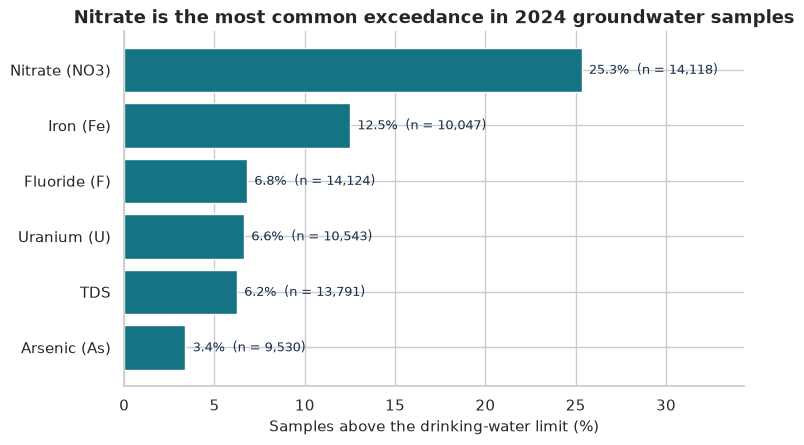

In [13]:
s = pd.Series(exceed).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.barh(s.index, s.values, color=TEAL)
for b, name in zip(bars, s.index):
    ax.text(b.get_width() + 0.4, b.get_y() + b.get_height() / 2, f'{b.get_width():.1f}%  (n = {n_measured[name]:,})', va='center', fontsize=9, color=NAVY)
ax.set_xlim(0, s.max() + 9)
ax.set_xlabel('Samples above the drinking-water limit (%)')
ax.set_title('Nitrate is the most common exceedance in 2024 groundwater samples')
sns.despine()
fig.savefig('charts/v1.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretation.** Nitrate exceeds its limit in 25.3% of the samples where it was measured, far more than any other parameter. Iron (12.5%), TDS (6.2%), uranium (6.6%) and fluoride (6.8%) follow, and arsenic is lowest at 3.4% but still serious where it occurs. Percentages use only samples that were measured, shown as *n*.

### Visualization 2: Heatmap, exceedance by state and parameter (Plotly, interactive)

In [14]:

rows, counts = {}, {}

for name, (col, lim, unit) in LIMITS.items():
    data = df[df['State'].isin(big_states)].dropna(subset=[col])

    grouped = data.groupby('State')[col]

    rows[name] = grouped.apply(lambda s: (s > lim).mean() * 100)
    counts[name] = grouped.count()

heat = pd.DataFrame(rows)
counts = pd.DataFrame(counts)

# Hide states with fewer than 30 samples
for name in heat.columns:
    heat.loc[counts[name] < 30, name] = np.nan

# Select the top 12 states
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
heat_plot = heat.head(12)
n_plot = counts.loc[heat_plot.index]

# Display percentage labels
labels = heat_plot.round(0).fillna(-1).astype(int).astype(str)
labels = labels.replace('-1', '')

# Create interactive heatmap
fig = go.Figure(go.Heatmap(
    z=heat_plot.values,
    x=heat_plot.columns,
    y=heat_plot.index,
    colorscale='YlOrRd',
    zmin=0,
    text=labels.values,
    texttemplate='%{text}',
    customdata=n_plot.values,
    hovertemplate='%{y}<br>%{x}<br>%{z:.1f}% above limit'
                  '<br>%{customdata} samples<extra></extra>',
    hoverongaps=False,
    colorbar=dict(title='Above limit (%)')
))

fig.update_yaxes(autorange='reversed')

fig.update_layout(
    title='Exceedance by State and Parameter - Top 12 States',
    height=560
)

fig.write_html('charts/v2_interactive_heatmap.html')
fig.show()


**Interpretation.** The problem differs sharply by state. Nitrate is highest in Gujarat (53%), Maharashtra (52%), Karnataka (47%); fluoride in Rajasthan (30%), Gujarat (29%), Delhi (24%); iron in West Bengal (43%), Uttarakhand (36%), Uttar Pradesh (27%); TDS in Delhi (46%), Gujarat (41%), Rajasthan (37%); and arsenic in West Bengal (20%), Bihar (11%), Punjab (9%). The chart shows the 12 states with the highest average exceedance (of 25 states with 100+ samples). Blank cells mean fewer than 30 measured samples, so no rate is shown. *Hover a cell to see the exact rate and how many samples it is based on.*

### Visualization 3: Histogram, distribution of nitrate (Matplotlib)

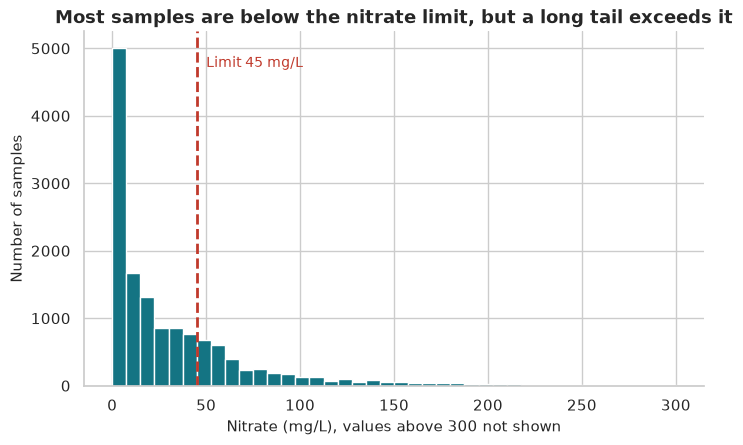

Median nitrate: 17 mg/L | 90th percentile: 85 mg/L | maximum: 2,408 mg/L | values above 300: 120


In [15]:
no3 = df['NO3_mgL'].dropna()
shown = no3[no3 <= 300]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(shown, bins=40, color=TEAL, edgecolor='white')
ax.axvline(45, color=RED, lw=2, ls='--')
ax.text(50, ax.get_ylim()[1] * 0.9, 'Limit 45 mg/L', color=RED, fontsize=10)
ax.set_xlabel('Nitrate (mg/L), values above 300 not shown'); ax.set_ylabel('Number of samples')
ax.set_title('Most samples are below the nitrate limit, but a long tail exceeds it')
sns.despine()
fig.savefig('charts/v3.png', dpi=200, bbox_inches='tight'); plt.show()
print(f'Median nitrate: {no3.median():.0f} mg/L | 90th percentile: {no3.quantile(.9):.0f} mg/L | maximum: {no3.max():,.0f} mg/L | values above 300: {(no3 > 300).sum()}')

**Interpretation.** The distribution is strongly right-skewed: the median nitrate is 17.0 mg/L, well under the limit, but a long tail pushes 25.3% of samples above 45 mg/L, with a maximum of 2408.0 mg/L. An average alone would hide these high-risk stations.

### Visualization 4: Boxplot, fluoride by state (Seaborn)

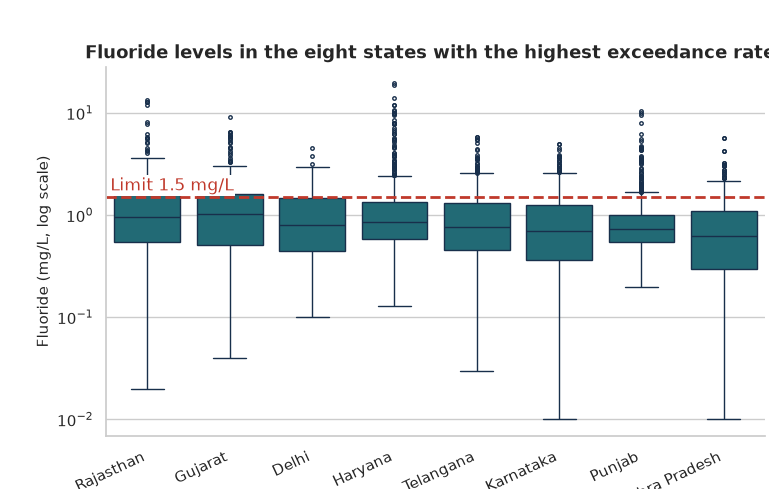

State
Rajasthan         0.95
Gujarat           1.02
Delhi             0.80
Haryana           0.85
Telangana         0.77
Karnataka         0.69
Punjab            0.74
Andhra Pradesh    0.63


In [16]:
fl = df[df['State'].isin(big_states)].dropna(subset=['F_mgL'])
top = fl.groupby('State')['F_mgL'].apply(lambda s: (s > 1.5).mean()).sort_values(ascending=False).head(8).index.tolist()
plot_df = fl[fl['State'].isin(top) & (fl['F_mgL'] > 0)]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.boxplot(data=plot_df, x='State', y='F_mgL', order=top, color=TEAL, linecolor=NAVY, fliersize=2.5, ax=ax)
ax.axhline(1.5, color=RED, lw=2, ls='--'); ax.text(-0.45, 1.75, 'Limit 1.5 mg/L', color=RED, ha='left', bbox=dict(facecolor='white', edgecolor='none', pad=1.5))
ax.set_yscale('log'); ax.set_ylabel('Fluoride (mg/L, log scale)'); ax.set_xlabel('')
ax.set_title('Fluoride levels in the eight states with the highest exceedance rates')
plt.xticks(rotation=25, ha='right'); sns.despine()
fig.savefig('charts/v4.png', dpi=200, bbox_inches='tight'); plt.show()
print(fl.groupby('State')['F_mgL'].median().loc[top].round(2).to_string())

**Interpretation.** Rajasthan and Gujarat lead on fluoride exceedance; among these states the median fluoride is highest in Gujarat (1.02 mg/L) against a limit of 1.5 mg/L. The log scale is used so both low medians and extreme outliers stay visible; samples with a reading of exactly zero are left out of this chart only.

### Visualization 5: Scatter plot, nitrate against EC (Plotly, interactive)

In [17]:

# Remove missing and invalid values
sc = df.dropna(subset=['EC_uS_cm', 'NO3_mgL'])
sc = sc[(sc['EC_uS_cm'] > 0) & (sc['NO3_mgL'] > 0)]

# Calculate Spearman correlation
rho = sc['EC_uS_cm'].corr(sc['NO3_mgL'], method='spearman')

# Create scatter plot
fig = go.Figure()

for limit, color, label in [
    (False, TEAL, 'Within nitrate limit'),
    (True, RED, 'Above nitrate limit')
]:
    s = sc[(sc['NO3_mgL'] > 45) == limit]

    fig.add_trace(go.Scatter(
        x=s['EC_uS_cm'],
        y=s['NO3_mgL'],
        mode='markers',
        name=label,
        marker=dict(size=4, color=color, opacity=0.35),
        text=s['Station'] + ', ' + s['District'] + ', ' + s['State'],
        hovertemplate='%{text}<br>EC: %{x:.0f} µS/cm'
                      '<br>Nitrate: %{y:.1f} mg/L<extra></extra>'
    ))

# Add nitrate limit
fig.add_hline(y=45, line_dash='dash', line_color=RED)

# Use logarithmic scales
fig.update_xaxes(type='log', title='Electrical Conductivity (µS/cm)')
fig.update_yaxes(type='log', title='Nitrate (mg/L)')

fig.update_layout(
    title=f'Nitrate vs EC (Spearman correlation = {rho:.2f})',
    height=560
)

fig.write_html('charts/v5_interactive_scatter.html')
fig.show()

# Group EC values into five levels
sc['EC_group'] = pd.qcut(
    sc['EC_uS_cm'], 5,
    labels=['Lowest', 'Low', 'Middle', 'High', 'Highest']
)

# Calculate percentage exceeding the nitrate limit
result = sc.groupby('EC_group', observed=False)['NO3_mgL'].apply(
    lambda x: (x > 45).mean() * 100
)

print(f'Spearman correlation: {rho:.3f}')
print(f'Samples plotted: {len(sc)}')
print('\nPercentage above nitrate limit by EC group:')
print(result.round(1))

# Check relationship between TDS and EC
ratio = (df['TDS_mgL'] / df['EC_uS_cm']).replace(
    [np.inf, -np.inf], np.nan
).dropna()

print(f'\nMedian TDS/EC ratio: {ratio.median():.2f}')


Spearman correlation: 0.518
Samples plotted: 12838

Percentage above nitrate limit by EC group:
EC_group
Lowest      3.9
Low        12.3
Middle     25.6
High       42.6
Highest    54.9
Name: NO3_mgL, dtype: float64

Median TDS/EC ratio: 0.65


**Interpretation.** Nitrate and EC rise together (Spearman rho = 0.52). The share of samples above the nitrate limit climbs from 3.9% in the lowest-EC fifth of samples to 54.9% in the highest. A quick EC reading is therefore a useful warning sign for nitrate, though many high-EC samples are still below the limit. This is association, not proof of cause. *Why not EC against TDS?* In this table TDS is mostly calculated from EC (TDS is about 0.65 times EC), so their near-perfect match is by construction and is not a finding. *Hover a point to see the station, district and season; drag to zoom into a region of the plot and double-click to reset.*

### Visualization 6: Line plot, pre-monsoon to post-monsoon (Plotly, interactive)

In [18]:

# Calculate percentage of samples above each limit by season
seas = {}
seas_n = {}

for name, (col, lim, unit) in LIMITS.items():
    data = df.dropna(subset=[col]).groupby('Season')[col]

    seas[name] = data.apply(lambda s: (s > lim).mean() * 100)
    seas_n[name] = data.count()

seas = pd.DataFrame(seas).T[['Pre-Monsoon', 'Post-Monsoon']]
seas_n = pd.DataFrame(seas_n).T[['Pre-Monsoon', 'Post-Monsoon']]

# Create line chart
fig = go.Figure()

colors = [TEAL, AMBER, NAVY, RED, '#7FB7BE', '#8E6BB0']

for i, name in enumerate(seas.index):
    values = seas.loc[name]

    fig.add_trace(go.Scatter(
        x=['Pre-Monsoon', 'Post-Monsoon'],
        y=values.values,
        mode='lines+markers',
        name=name,
        line=dict(color=colors[i % len(colors)], width=3),
        marker=dict(size=8),
        customdata=seas_n.loc[name].values,
        hovertemplate=(
            '<b>' + name + '</b><br>%{x}: %{y:.1f}%'
            '<br>Samples: %{customdata}<extra></extra>'
        )
    ))

# Add percentage labels
    for season in ['Pre-Monsoon', 'Post-Monsoon']:
        fig.add_annotation(
            x=season,
            y=seas.loc[name, season],
            text=f'{seas.loc[name, season]:.1f}%',
            showarrow=False,
            yshift=12,
            font=dict(color=colors[i % len(colors)], size=10)
        )

# Format chart
fig.update_layout(
    title='Exceedance Rates by Season',
    xaxis_title='Season',
    yaxis_title='Samples Above the Limit (%)',
    height=520,
    hovermode='closest'
)

fig.write_html('charts/v6_interactive_seasons.html')
fig.show()

# Display results
print('Exceedance percentages by season:')
print(seas.round(1).to_string())


Exceedance percentages by season:
Season         Pre-Monsoon  Post-Monsoon
Nitrate (NO3)         24.0          26.7
Fluoride (F)           7.6           5.9
TDS                    6.6           5.8
Iron (Fe)             11.4          13.8
Uranium (U)            6.3           7.0
Arsenic (As)           3.4           3.4


**Interpretation.** Nitrate (NO3) rises most from pre- to post-monsoon (24.0% to 26.7%), while Fluoride (F) changes the other way (7.6% to 5.9%); the other parameters move by a few points at most. The two seasons use different stations in places, so the comparison shows broad direction, not a controlled before-and-after test. *Hover a point to see the exact rate and the number of samples behind it in that season.*

## 7b. Additional visualizations
Five more charts that cover what the first six do not: where the problems are on the ground, a fair season comparison, whether problems stack up in the same samples, how all parameters relate, and what type of water each sample is.

### Visualization 7: Station map, exceedance by location (Matplotlib)

In [19]:
# Interactive station map: one panel per parameter, red where the sample is above the limit; hover a point for details
from plotly.subplots import make_subplots
titles = []
for name, (col, lim, unit) in LIMITS.items():
    d = df.dropna(subset=[col, 'Latitude', 'Longitude'])
    titles.append(f'<b>{name}</b>: {(d[col] > lim).mean() * 100:.1f}% above {lim:g} {unit}')
fig = make_subplots(rows=2, cols=3, subplot_titles=titles, horizontal_spacing=0.02, vertical_spacing=0.07)
for k, (name, (col, lim, unit)) in enumerate(LIMITS.items()):
    r, c = k // 3 + 1, k % 3 + 1
    d = df.dropna(subset=[col, 'Latitude', 'Longitude'])
    for above, color, label, size in [(False, '#C9D3DC', 'Within limit', 3), (True, RED, 'Above limit', 4)]:
        s = d[(d[col] > lim) == above]
        fig.add_trace(go.Scattergl(
            x=s['Longitude'], y=s['Latitude'], mode='markers', name=label, legendgroup=label, showlegend=(k == 0),
            marker=dict(size=size, color=color, opacity=.8 if above else .6),
            customdata=s[['Station', 'District', 'State', 'Season', col]].values,
            hovertemplate='<b>%{customdata[0]}</b><br>%{customdata[1]}, %{customdata[2]}<br>%{customdata[3]}<br>'
                          + f'{name}: ' + '%{customdata[4]:.2f} ' + f'{unit} (limit {lim:g})<extra></extra>'), row=r, col=c)
    axis = '' if k == 0 else str(k + 1)
    fig.update_xaxes(visible=False, range=[67.5, 97.5], row=r, col=c)
    fig.update_yaxes(visible=False, range=[6, 37.5], scaleanchor='x' + axis, scaleratio=1.05, row=r, col=c)
fig.update_annotations(font_size=13)
fig.update_layout(title=dict(text='<b>Where samples exceed drinking-water limits</b> (grey = within limit, red = above; hover a point, drag to zoom)', x=0.5),
                  height=900, plot_bgcolor='white', legend=dict(orientation='h', x=0.5, xanchor='center', y=-0.02, itemsizing='constant'),
                  margin=dict(l=10, r=10, t=80, b=40), font=dict(family='DejaVu Sans'))
fig.write_html('charts/v7_interactive_station_map.html', include_plotlyjs='cdn')
fig.show()
print('Stations with usable coordinates:', int(df[['Latitude', 'Longitude']].notna().all(axis=1).sum()), 'of', len(df))

Stations with usable coordinates: 15154 of 15185


**Interpretation.** The map shows that each problem sits in its own region, not spread evenly. Nitrate is the most widespread and covers much of peninsular India and the north-west. Uranium is packed into one tight cluster in Punjab and Haryana. Arsenic follows the Ganga plain into West Bengal and Bihar, with a second pocket in Punjab. Iron runs along the Gangetic plain, the North-East, Odisha and the Kerala coast. Fluoride and TDS are strongest in Rajasthan, Gujarat and the interior of Telangana and Andhra Pradesh. Dot density reflects where CGWB has stations, not the size of the problem, so the map is read alongside the percentages. The nitrate figure (25.4%) differs slightly from Visualization 1 because 31 rows have no valid coordinates.

### Visualization 8: Paired dumbbell chart, same stations in both seasons (Matplotlib)

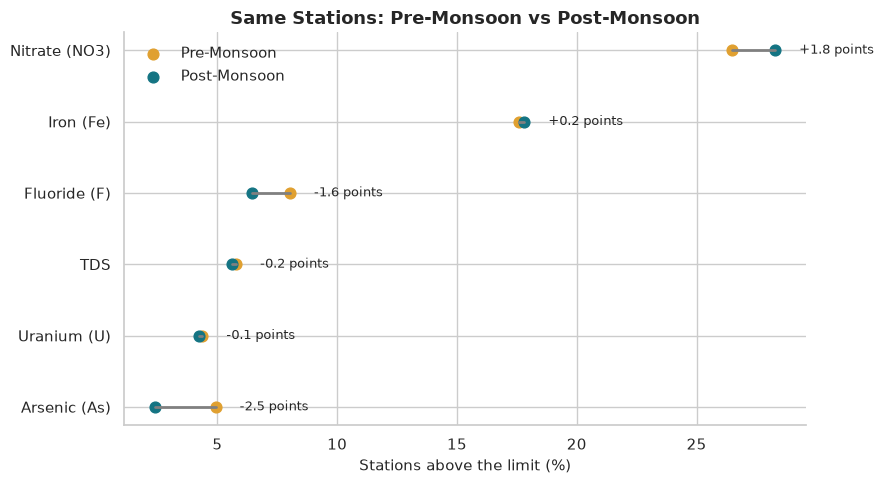

Stations sampled in both seasons: 4001

Exceedance comparison:
               Stations   Pre  Post
Parameter                          
Arsenic (As)       1663   4.9   2.4
Uranium (U)        2034   4.4   4.2
TDS                3735   5.8   5.6
Fluoride (F)       3735   8.0   6.4
Iron (Fe)          1819  17.6  17.8
Nitrate (NO3)      3734  26.5  28.3

Station transition details:
               Stations  Safe both  Above both  Became unsafe  Became safe
Parameter                                                                 
Nitrate (NO3)      3734       2377         688            368          301
Fluoride (F)       3735       3344         149             91          151
TDS                3735       3428         119             91           97
Iron (Fe)          1819       1325         150            174          170
Uranium (U)        2034       1887          28             58           61
Arsenic (As)       1663       1572          31              9           51


In [20]:

# Find stations sampled in both seasons
key = ['State', 'District', 'Block', 'Station']

both = df.groupby(key, dropna=False)['Season'].transform('nunique') == 2

pair_rows = []
trans = []

for name, (col, lim, unit) in LIMITS.items():

    # Calculate average values for each station in each season
    w = df[both].dropna(subset=[col]).groupby(
        key + ['Season'], dropna=False
    )[col].mean().unstack('Season')

    w = w.dropna(subset=['Pre-Monsoon', 'Post-Monsoon'])

    pre = w['Pre-Monsoon'] > lim
    post = w['Post-Monsoon'] > lim

    # Percentage above the limit
    pair_rows.append({
        'Parameter': name,
        'Stations': len(w),
        'Pre': pre.mean() * 100,
        'Post': post.mean() * 100
    })

    # Track changes between seasons
    trans.append({
        'Parameter': name,
        'Stations': len(w),
        'Safe both': (~pre & ~post).sum(),
        'Above both': (pre & post).sum(),
        'Became unsafe': (~pre & post).sum(),
        'Became safe': (pre & ~post).sum()
    })

# Create results table
pair = pd.DataFrame(pair_rows).sort_values('Post')

# Draw comparison chart
fig, ax = plt.subplots(figsize=(9, 5))

for i, row in enumerate(pair.itertuples()):
    ax.plot([row.Pre, row.Post], [i, i], color='grey', linewidth=2)
    ax.scatter(row.Pre, i, color=AMBER, s=60,
               label='Pre-Monsoon' if i == 0 else '')
    ax.scatter(row.Post, i, color=TEAL, s=60,
               label='Post-Monsoon' if i == 0 else '')

    ax.text(max(row.Pre, row.Post) + 1, i,
            f'{row.Post - row.Pre:+.1f} points',
            va='center', fontsize=9)

ax.set_yticks(range(len(pair)))
ax.set_yticklabels(pair['Parameter'])
ax.set_xlabel('Stations above the limit (%)')
ax.set_title('Same Stations: Pre-Monsoon vs Post-Monsoon')
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()

# Save and display chart
plt.savefig('charts/v8.png', dpi=200, bbox_inches='tight')
plt.show()

# Display results
print('Stations sampled in both seasons:',
      df[both].groupby(key, dropna=False).ngroups)

print('\nExceedance comparison:')
print(pair.set_index('Parameter').round(1).to_string())

print('\nStation transition details:')
print(pd.DataFrame(trans).set_index('Parameter').to_string())


**Interpretation.** Visualization 6 compared different sets of stations in the two seasons. This chart keeps only the 4,001 stations sampled in both, so the comparison is like for like. The result agrees with Visualization 6: nitrate rises from 26.5% to 28.3%, fluoride falls from 8.0% to 6.4%, and arsenic halves from 4.9% to 2.4%. TDS, iron and uranium barely move. The national rate hides a lot of movement at individual wells, though. For nitrate, 368 stations went from safe to unsafe and 301 went the other way, so about 18% of stations changed status between seasons. One round of sampling is enough for the national picture, but not for judging a single well.

### Visualization 9: Multiple exceedances per sample (Matplotlib)

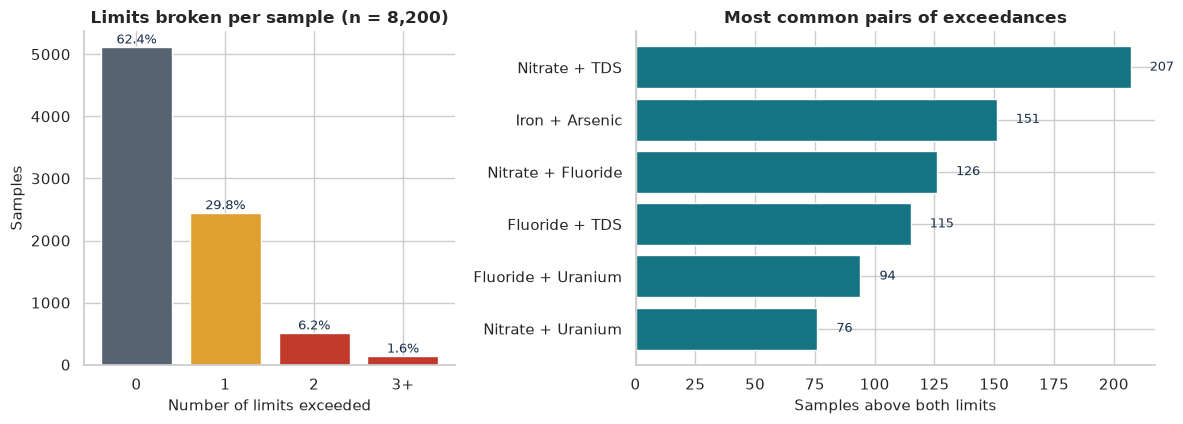

Samples measured for all six: 8,200
Limits exceeded per sample: {0: 5113, 1: 2444, 2: 508, 3: 112, 4: 22, 5: 1}
At least one: 37.6% | two or more: 7.8%
Nitrate + TDS         207
Iron + Arsenic        151
Nitrate + Fluoride    126
Fluoride + TDS        115
Fluoride + Uranium     94
Nitrate + Uranium      76


In [21]:
# How many limits does each sample break? Only samples measured for all six parameters
full = df[df[flag_cols].notna().all(axis=1)]
k = full[flag_cols].sum(axis=1).astype(int)
counts = k.value_counts().sort_index()
counts = pd.concat([counts[counts.index < 3], pd.Series({'3+': counts[counts.index >= 3].sum()})])
short = {('Exceeds_' + c): n.split(' (')[0] for n, (c, _, _) in LIMITS.items()}
pairs = {}
cols = list(short)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        pairs[f'{short[a]} + {short[b]}'] = int(((full[a] == 1) & (full[b] == 1)).sum())
pairs = pd.Series(pairs).sort_values().tail(6)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={'width_ratios': [1, 1.4]})
b = a1.bar(counts.index.astype(str), counts.values, color=[GREY, AMBER, RED, RED])
for r in b: a1.text(r.get_x() + r.get_width() / 2, r.get_height() + 60, f'{r.get_height() / len(full) * 100:.1f}%', ha='center', fontsize=9, color=NAVY)
a1.set_xlabel('Number of limits exceeded'); a1.set_ylabel('Samples')
a1.set_title(f'Limits broken per sample (n = {len(full):,})', fontsize=12)
a2.barh(pairs.index, pairs.values, color=TEAL)
for i, v in enumerate(pairs.values): a2.text(v + 8, i, f'{v}', va='center', fontsize=9, color=NAVY)
a2.set_xlabel('Samples above both limits'); a2.set_title('Most common pairs of exceedances', fontsize=12)
sns.despine(); fig.tight_layout()
fig.savefig('charts/v9.png', dpi=200, bbox_inches='tight'); plt.show()
print(f'Samples measured for all six: {len(full):,}')
print('Limits exceeded per sample:', k.value_counts().sort_index().to_dict())
print(f'At least one: {(k >= 1).mean() * 100:.1f}% | two or more: {(k >= 2).mean() * 100:.1f}%')
print(pairs.sort_values(ascending=False).to_string())

**Interpretation.** This uses only the 8,200 samples measured for all six parameters, so every sample had the same chance to fail. 37.6% break at least one limit, and 7.8% (643 samples) break two or more. The most common pair is nitrate with TDS (207 samples), which fits the link between nitrate and salinity in Visualization 5. Next is iron with arsenic (151), which is expected because both are released from aquifer sediments under the same low-oxygen conditions. Where one of these is found, the other is worth testing for.

### Visualization 10: Correlation heatmap of all parameters (Seaborn)

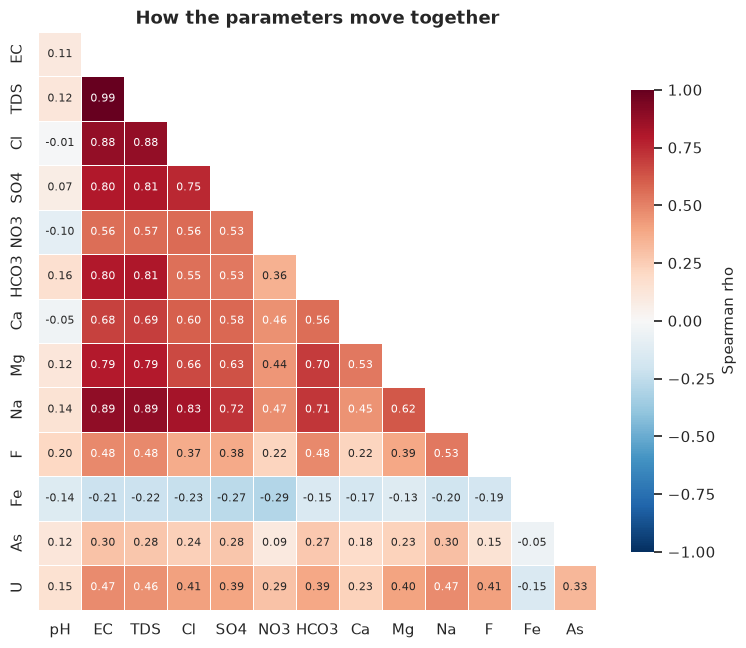

Strongest positive:
TDS  EC     0.99
Na   EC     0.89
     TDS    0.89
Cl   EC     0.88
     TDS    0.88
Na   Cl     0.83
Most negative:
Fe  NO3   -0.29
    SO4   -0.27
    Cl    -0.23
F vs EC: 0.48
As vs EC: 0.30
U vs EC: 0.47
Fe vs EC: -0.21


In [22]:
# Spearman correlation between the main parameters (rank-based, so outliers do not dominate)
corr_cols = {'pH': 'pH', 'EC_uS_cm': 'EC', 'TDS_mgL': 'TDS', 'Cl_mgL': 'Cl', 'SO4_mgL': 'SO4', 'NO3_mgL': 'NO3',
             'HCO3_mgL': 'HCO3', 'Ca_mgL': 'Ca', 'Mg_mgL': 'Mg', 'Na_mgL': 'Na', 'F_mgL': 'F',
             'Fe_mgL': 'Fe', 'As_ppb': 'As', 'U_ppb': 'U'}
cm = df[list(corr_cols)].rename(columns=corr_cols).corr(method='spearman')
mask = np.triu(np.ones_like(cm, dtype=bool))
show, show_mask = cm.iloc[1:, :-1], mask[1:, :-1]          # drop the empty first row and last column
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(show, mask=show_mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, linewidths=.5,
            linecolor='white', annot_kws={'fontsize': 8}, cbar_kws={'label': 'Spearman rho', 'shrink': .8}, ax=ax)
ax.grid(False); ax.set_title('How the parameters move together')
fig.savefig('charts/v10.png', dpi=200, bbox_inches='tight'); plt.show()
pairs_c = cm.where(~mask).stack().dropna().sort_values()
print('Strongest positive:'); print(pairs_c.tail(6)[::-1].round(2).to_string())
print('Most negative:'); print(pairs_c.head(3).round(2).to_string())
for p in ['F', 'As', 'U', 'Fe']:
    print(f'{p} vs EC: {cm.loc[p, "EC"]:.2f}')

**Interpretation.** EC and TDS correlate at 0.99, which confirms that TDS in this table is calculated from EC. Sodium, chloride, sulphate, bicarbonate and magnesium all track EC closely (0.79 to 0.89), so these major ions are what make the water saline. Nitrate (0.56), fluoride (0.48) and uranium (0.47) are moderately linked to salinity. Arsenic is only weakly linked (0.30), so an EC reading cannot screen for it. Iron is the only parameter with a negative relation to almost everything (-0.13 to -0.29), which points to a different source from the salinity-related contaminants.

### Visualization 11: Piper diagram, water type (Matplotlib)

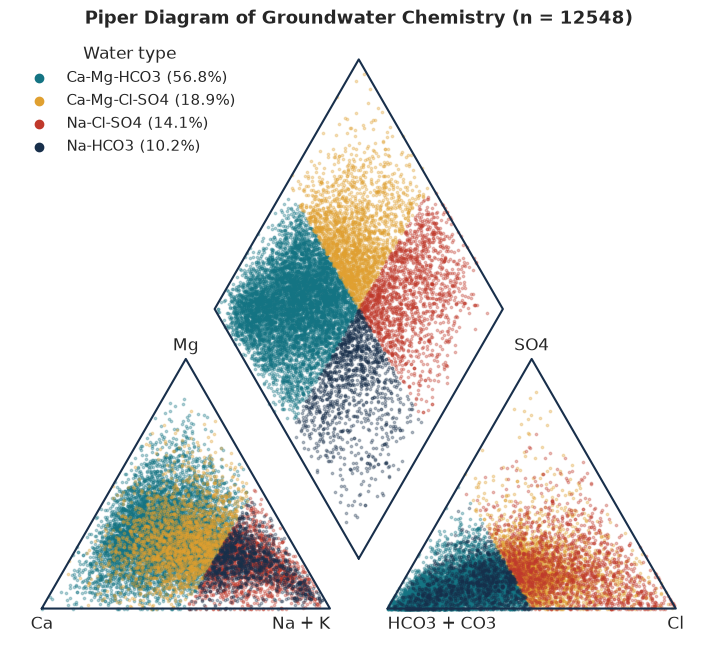

Groundwater types (%):
Ca-Mg-HCO3      56.8
Ca-Mg-Cl-SO4    18.9
Na-Cl-SO4       14.1
Na-HCO3         10.2

Nitrate exceedance by water type (%):
Water type
Ca-Mg-Cl-SO4    44.0
Ca-Mg-HCO3      16.1
Na-Cl-SO4       39.0
Na-HCO3         23.1


In [23]:

# Convert major ions from mg/L to milliequivalents per litre (meq/L)
meq = {
    'Ca_mgL': 20.04, 'Mg_mgL': 12.15,
    'Na_mgL': 22.99, 'K_mgL': 39.10,
    'HCO3_mgL': 61.02, 'CO3_mgL': 30.00,
    'Cl_mgL': 35.45, 'SO4_mgL': 48.03
}

pw = df.dropna(subset=list(meq)).copy()
pw = pw[(pw[list(meq)] >= 0).all(axis=1)]

for col, factor in meq.items():
    pw[col] = pw[col] / factor

# Calculate total cations and anions
cat = pw[['Ca_mgL', 'Mg_mgL', 'Na_mgL', 'K_mgL']].sum(axis=1)
an = pw[['HCO3_mgL', 'CO3_mgL', 'Cl_mgL', 'SO4_mgL']].sum(axis=1)

pw = pw[(cat > 0) & (an > 0)]
cat, an = cat.loc[pw.index], an.loc[pw.index]

# Calculate ion percentages
ca = pw['Ca_mgL'] / cat
mg = pw['Mg_mgL'] / cat
na = (pw['Na_mgL'] + pw['K_mgL']) / cat

hco3 = (pw['HCO3_mgL'] + pw['CO3_mgL']) / an
cl = pw['Cl_mgL'] / an
so4 = pw['SO4_mgL'] / an

# Classify groundwater types
types = np.select(
    [
        (ca + mg >= 0.5) & (hco3 >= 0.5),
        (ca + mg >= 0.5) & (hco3 < 0.5),
        (ca + mg < 0.5) & (hco3 < 0.5)
    ],
    ['Ca-Mg-HCO3', 'Ca-Mg-Cl-SO4', 'Na-Cl-SO4'],
    default='Na-HCO3'
)

# Set colors
colors = {
    'Ca-Mg-HCO3': TEAL,
    'Ca-Mg-Cl-SO4': AMBER,
    'Na-Cl-SO4': RED,
    'Na-HCO3': NAVY
}

# Calculate positions for the Piper diagram
h = np.sqrt(3) / 2
gap = 0.2

# Cation triangle
xc = na + 0.5 * mg
yc = h * mg

# Anion triangle
xa = 1 + gap + cl + 0.5 * so4
ya = h * so4

# Central diamond
bx, by = 1 + gap / 2, h * gap
xd = bx + 0.5 * (cl + so4) - 0.5 * (ca + mg)
yd = by + h * (cl + so4) + h * (ca + mg)

# Draw the diagram
fig, ax = plt.subplots(figsize=(9, 9))

ax.plot([0, 1, 0.5, 0], [0, 0, h, 0], color=NAVY)
ax.plot(
    [1 + gap, 2 + gap, 1.5 + gap, 1 + gap],
    [0, 0, h, 0], color=NAVY
)
ax.plot(
    [bx, bx + 0.5, bx, bx - 0.5, bx],
    [by, by + h, by + 2*h, by + h, by],
    color=NAVY
)

# Plot each groundwater type
for water_type, color in colors.items():
    selected = types == water_type

    ax.scatter(xc[selected], yc[selected], color=color, s=3, alpha=0.3)
    ax.scatter(xa[selected], ya[selected], color=color, s=3, alpha=0.3)
    ax.scatter(xd[selected], yd[selected], color=color, s=3, alpha=0.3)

    ax.scatter(
        [], [], color=color,
        label=f'{water_type} ({selected.mean()*100:.1f}%)'
    )

# Add ion labels
ax.text(0, -0.07, 'Ca', ha='center')
ax.text(1, -0.07, 'Na + K', ha='right')
ax.text(0.5, h + 0.03, 'Mg', ha='center')

ax.text(1 + gap, -0.07, 'HCO3 + CO3', ha='left')
ax.text(2 + gap, -0.07, 'Cl', ha='center')
ax.text(1.5 + gap, h + 0.03, 'SO4', ha='center')

ax.set_aspect('equal')
ax.axis('off')
ax.legend(title='Water type', loc='upper left', frameon=False)
ax.set_title(f'Piper Diagram of Groundwater Chemistry (n = {len(pw)})')

plt.savefig('charts/v11.png', dpi=200, bbox_inches='tight')
plt.show()

# Display water type percentages
print('Groundwater types (%):')
print(
    pd.Series(types).value_counts(normalize=True)
    .mul(100).round(1).to_string()
)

# Compare nitrate exceedance by water type
nit_by_type = pd.DataFrame({
    'Water type': types,
    'Above limit': df.loc[pw.index, 'NO3_mgL'].values > 45
})

print('\nNitrate exceedance by water type (%):')
print(
    nit_by_type.groupby('Water type')['Above limit']
    .mean().mul(100).round(1).to_string()
)


**Interpretation.** Each sample is plotted three times: its cations (left triangle), its anions (right triangle), and the combined position in the diamond, which gives the water type. Ion values are converted to milliequivalents per litre first, and the 3 rows with a negative ion value are dropped. Most samples (57%) are Ca-Mg-HCO3, the usual type for fresh, recently recharged groundwater. The rest are Ca-Mg-Cl-SO4 (19%), Na-Cl-SO4 (14%) and Na-HCO3 (10%). The water type matters for quality: 44% of Ca-Mg-Cl-SO4 samples and 39% of Na-Cl-SO4 samples are above the nitrate limit, against only 16% of Ca-Mg-HCO3 samples. This uses a simple four-type split at 50%, not the full nine-zone Piper classification.

## 7c. Interactive charts (Plotly)
Visualizations 2, 5 and 6 above are already interactive. These two add Plotly charts with a parameter dropdown, so the reader can explore the data inside the notebook: hover any point or bar for its exact values, and use the dropdown to switch parameter. Each chart is also saved as a standalone HTML file in `charts/` that opens in any browser.

### Visualization 12: Interactive station map (Plotly)

In [24]:
# Interactive treemap: states sized by samples measured, coloured by exceedance; click a state to see its districts
traces, buttons = [], []
names = list(LIMITS)
for k, (name, (col, lim, unit)) in enumerate(LIMITS.items()):
    d = df.dropna(subset=[col]).copy()
    d['District'] = d['District'].fillna('Unknown')
    d['above'] = d[col] > lim
    dist = d.groupby(['State', 'District'])['above'].agg(Samples='count', Exceeding='sum').reset_index()
    st = d.groupby('State')['above'].agg(Samples='count', Exceeding='sum').reset_index()
    ids = list(st['State']) + list(dist['State'] + ' / ' + dist['District'])
    labels = list(st['State']) + list(dist['District'])
    parents = [''] * len(st) + list(dist['State'])
    samples = list(st['Samples']) + list(dist['Samples'])
    exceeding = list(st['Exceeding']) + list(dist['Exceeding'])
    pct = [e / s * 100 for e, s in zip(exceeding, samples)]
    cmax = max(5, min(100, np.ceil(st['Exceeding'].div(st['Samples']).max() * 110)))   # colour range set by the worst state
    traces.append(go.Treemap(
        ids=ids, labels=labels, parents=parents, values=samples, branchvalues='total',
        marker=dict(colors=pct, colorscale='YlOrRd', cmin=0, cmax=cmax, line=dict(color='white', width=1),
                    colorbar=dict(title=dict(text='Samples above<br>limit (%)'))),
        customdata=np.column_stack([pct, exceeding]),
        texttemplate='<b>%{label}</b><br>%{customdata[0]:.0f}%',
        hovertemplate='<b>%{label}</b><br>%{customdata[0]:.1f}% above the limit<br>%{customdata[1]:.0f} of %{value:,} samples<extra></extra>',
        maxdepth=2, visible=(k == 0), name=name))
    overall = d['above'].mean() * 100
    buttons.append(dict(label=name, method='update',
                        args=[{'visible': [i == k for i in range(len(names))]},
                              {'title.text': f'<b>{name}: {overall:.1f}% of samples above {lim:g} {unit}</b>'}]))
c0, l0, u0 = LIMITS[names[0]]
first = df.dropna(subset=[c0])
fig = go.Figure(traces)
fig.update_layout(title=dict(text=f'<b>{names[0]}: {(first[c0] > l0).mean() * 100:.1f}% of samples above {l0:g} {u0}</b>', x=0.01, xanchor='left'),
                  updatemenus=[dict(buttons=buttons, x=1.0, y=1.09, xanchor='right', yanchor='bottom', bgcolor='white')],
                  annotations=[dict(text='Box size = samples measured, colour = % above the limit. Click a state to see its districts; click the top bar to go back.',
                                    x=0.01, y=1.045, xref='paper', yref='paper', xanchor='left', yanchor='bottom', showarrow=False, font=dict(size=12, color=GREY))],
                  height=720, margin=dict(l=10, r=10, t=125, b=10), font=dict(family='DejaVu Sans'))
fig.write_html('charts/v12_interactive_treemap.html', include_plotlyjs='cdn')
fig.show()

**How to use it.** Pick a parameter from the dropdown at the top left. Red points are samples above the limit, grey points are within it. Hover a point to see the station, district, state, season and measured value. Scroll to zoom into a region, for example West Bengal for arsenic or Punjab for uranium, and double-click to reset. Clicking a legend entry hides that group, so you can show only the stations above the limit. It is the same data as Visualization 7, but you can look up individual stations.

### Visualization 13: Interactive state ranking (Plotly)

In [25]:

# Create chart traces and dropdown buttons
traces = []
buttons = []
names = list(LIMITS.keys())

for i, (name, (col, lim, unit)) in enumerate(LIMITS.items()):

    # Calculate samples and exceedances for each state
    data = df.dropna(subset=[col]).groupby('State')[col]

    g = data.agg(
        Samples='count',
        Exceeding=lambda s: (s > lim).sum()
    ).reset_index()

    # Keep states with at least 30 samples
    g = g[g['Samples'] >= 30]

    # Calculate exceedance percentage and sort states
    g['Pct'] = g['Exceeding'] / g['Samples'] * 100
    g = g.sort_values('Pct')

    # Create horizontal bar chart
    traces.append(go.Bar(
        x=g['Pct'],
        y=g['State'],
        orientation='h',
        marker_color=TEAL,
        text=g['Pct'].round(1).astype(str) + '%',
        textposition='outside',
        customdata=g[['Samples', 'Exceeding']].values,
        hovertemplate=(
            '<b>%{y}</b><br>'
            '%{x:.1f}% above limit<br>'
            '%{customdata[1]} of %{customdata[0]} samples'
            '<extra></extra>'
        ),
        visible=(i == 0),
        name=name
    ))

    # Add dropdown option
    visible = [False] * len(names)
    visible[i] = True

    buttons.append(dict(
        label=name,
        method='update',
        args=[
            {'visible': visible},
            {'title': f'{name}: Percentage Above Limit by State ({lim:g} {unit})'}
        ]
    ))

# Create figure
first = names[0]
col, lim, unit = LIMITS[first]

fig = go.Figure(traces)

fig.update_layout(
    title=f'{first}: Percentage Above Limit by State',
    updatemenus=[dict(buttons=buttons, x=1, y=1.12)],
    xaxis_title='Samples Above the Limit (%)',
    yaxis_title='State',
    showlegend=False,
    height=820
)

# Save and display chart
fig.write_html('charts/v13_interactive_state_ranking.html')
fig.show()


**How to use it.** The dropdown switches between the six parameters, and the states re-rank automatically. Hover a bar to see how many samples were measured and how many were above the limit, so a high rate from a small sample is easy to spot. Only states with at least 30 measured samples are shown. This turns the static heatmap in Visualization 2 into a full ranking for every state and parameter.

## 8. Misleading visualization and ethical redesign
The chart below compares nitrate exceedance in the five largest-rate states (states with 100+ samples). The **misleading** version starts its axis above zero, which exaggerates the differences between bars. The **corrected** version starts at zero.

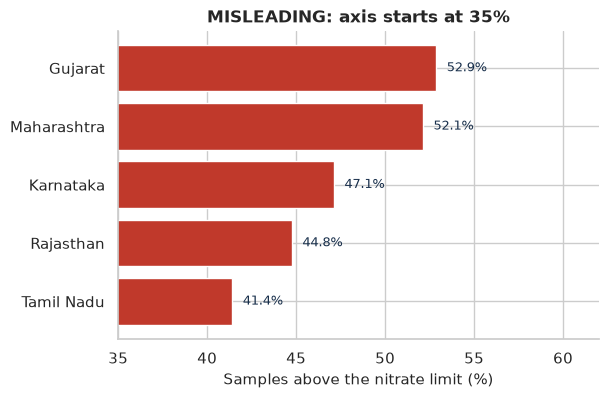

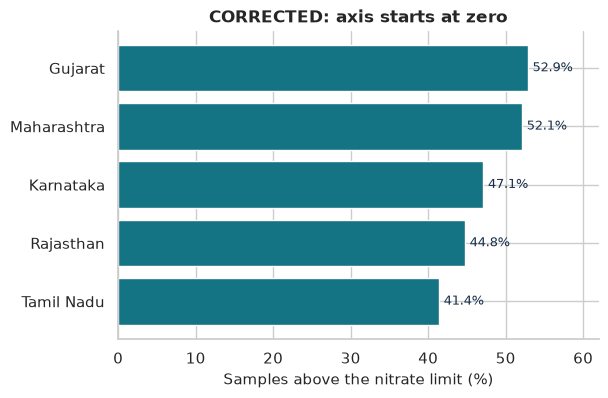

State
Tamil Nadu     41.4
Rajasthan      44.8
Karnataka      47.1
Maharashtra    52.1
Gujarat        52.9
Visual ratio top/bottom on the truncated chart: 2.8x | true ratio: 1.28x


In [26]:
nit = df[df['State'].isin(big_states)].dropna(subset=['NO3_mgL']).groupby('State')['NO3_mgL'].apply(lambda s: (s > 45).mean() * 100)
t5 = nit.sort_values(ascending=False).head(5).sort_values()
base = 35
for name, xmin, title, col in [('mis', base, f'MISLEADING: axis starts at {base}%', RED), ('eth', 0, 'CORRECTED: axis starts at zero', TEAL)]:
    fig, ax = plt.subplots(figsize=(6.2, 4))
    ax.barh(t5.index, t5.values, color=col)
    for i, v in enumerate(t5.values): ax.text(v + .6, i, f'{v:.1f}%', va='center', fontsize=9, color=NAVY)
    ax.set_xlim(xmin, 62); ax.set_xlabel('Samples above the nitrate limit (%)'); ax.set_title(title, fontsize=12); sns.despine()
    fig.savefig(f'charts/{name}.png', dpi=200, bbox_inches='tight'); plt.show()
visual = (t5.max() - base) / (t5.min() - base); true = t5.max() / t5.min()
print(t5.round(1).to_string())
print(f'Visual ratio top/bottom on the truncated chart: {visual:.1f}x | true ratio: {true:.2f}x')

**How it misleads.** Bar length is read as magnitude from a common baseline. Cutting the axis at 35% makes the top state (Gujarat, 52.9%) look about 2.8 times as large as the lowest (Tamil Nadu, 41.4%), but the true ratio is only 1.28 to 1. A small gap looks like a huge one.

**Correction.** The zero-based chart makes bar length match the value, so the five states are clearly high and close to each other. Principle applied: bar charts must start at zero, and a truncated axis is only acceptable when the chart does not encode value as length, and is clearly marked.

In [27]:
# Export key numbers for the report and slides
no3 = df['NO3_mgL'].dropna()
facts = {
 'n_raw': n_raw, 'n_clean': len(df), 'states_raw': states_raw, 'states_clean': int(df['State'].nunique()),
 'n_dups': n_dups, 'n_swapped': int(swap.sum()), 'n_badcoord': int(bad.sum()),
 'n_pre': int((df['Season'] == 'Pre-Monsoon').sum()), 'n_post': int((df['Season'] == 'Post-Monsoon').sum()),
 'n_states100': len(big_states),
 'exceed': exceed, 'n_measured': n_measured,
 'no3_median': float(no3.median()), 'no3_max': float(no3.max()),
 'rho': round(float(rho), 2), 'ec_low': round(float(ec_bins.iloc[0]), 1), 'ec_high': round(float(ec_bins.iloc[-1]), 1), 'tds_ratio': round(float(tds_ratio.median()), 2),
 'seas': {k: [float(v.iloc[0]), float(v.iloc[1])] for k, v in seas.iterrows()},
 'heat': {p: {s: (None if pd.isna(v) else float(v)) for s, v in heat[p].items()} for p in heat.columns},
 'mis': {'states': t5.index.tolist(), 'vals': [float(v) for v in t5.values], 'visual': float(visual), 'true': float(true), 'base': base},
 'fl_top': top, 'fl_median': {k: float(v) for k, v in fl.groupby('State')['F_mgL'].median().loc[top].items()},
 'missing_pct': {k: float(v) for k, v in missing[missing > 0].items()},
 'state_counts': {k: int(v) for k, v in state_n.items()},
 'any_exceed_pct': float((df[flag_cols].max(axis=1, skipna=True).where(df[flag_cols].notna().any(axis=1)).mean()) * 100),
}
json.dump(facts, open('facts.json', 'w'), indent=1)
print('facts saved; samples with at least one exceedance (of those with any measurement): %.1f%%' % facts['any_exceed_pct'])

NameError: name 'ec_bins' is not defined

## 9. Interactive dashboard (Tableau)
The dashboard is built in Tableau from `Tableau_State_Season_Parameter.csv` (State, Season, Parameter, Limit, Unit, Samples, Exceeding, Exceedance_Pct) and the cleaned station file `CGWB_Groundwater_Quality_2024_Cleaned.csv` (for the station map). The step-by-step build is in `Tableau_Dashboard_Build_Guide.md`. Filters: Season, Parameter, State. Interaction: clicking a state filters every chart.

## 10. Key findings and recommendations
1. Nitrate is the most widespread problem, followed by iron, TDS, uranium and fluoride; arsenic is rarer but concentrated in specific states.
2. Exceedance patterns are regional: the parameter that matters most differs by state, so one national response would miss the main issue in each region.
3. Season matters little at the national level for most parameters, so a single seasonal snapshot is a reasonable screen, though local seasonal swings remain.
4. Nitrate rises with salinity (EC), so EC is a useful warning sign for nitrate, but it cannot replace direct tests for fluoride or arsenic. TDS in this table is largely derived from EC and adds little independent information.

**Recommendations.** Prioritise nitrate management in the highest-rate states, target fluoride and arsenic treatment by state, continue both seasonal rounds, and publish station-level data in a machine-readable format instead of a PDF.

**Limitations.** One year of data; station sampling differs between seasons; many metal columns are mostly blank; exceedance rates describe monitored stations, not the whole population's exposure.